In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv('/credit.csv')
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,0,67,male,2,own,NaN,little,1169,6,radio/TV
1,1,22,female,2,own,little,moderate,5951,48,radio/TV
2,2,49,male,1,own,little,NaN,2096,12,education
3,3,45,male,2,free,little,little,7882,42,furniture/equipment
4,4,53,male,2,free,little,little,4870,24,car


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        1000 non-null   int64 
 1   Age               1000 non-null   int64 
 2   Sex               1000 non-null   object
 3   Job               1000 non-null   int64 
 4   Housing           1000 non-null   object
 5   Saving accounts   817 non-null    object
 6   Checking account  606 non-null    object
 7   Credit amount     1000 non-null   int64 
 8   Duration          1000 non-null   int64 
 9   Purpose           1000 non-null   object
dtypes: int64(5), object(5)
memory usage: 78.3+ KB


,Unnamed: 0,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,35.546000,1.904000,3271.258000,20.903000
std,288.819436,11.375469,0.653614,2822.736876,12.058814
min,0.000000,19.000000,0.000000,250.000000,4.000000
25%,249.750000,27.000000,2.000000,1365.500000,12.000000
50%,499.500000,33.000000,2.000000,2319.500000,18.000000
75%,749.250000,42.000000,2.000000,3972.250000,24.000000
max,999.000000,75.000000,3.000000,18424.000000,72.000000


In [4]:
unique_values = df['Checking account'].dropna().unique()

sorted_values = sorted(unique_values)
print('Уникальные значения: ')
for value in sorted_values:
  print(f'- {value}')

Уникальные значения: 
- little
- moderate
- rich


Препроцессинг категориальных признаков


In [5]:
df['is_male'] = (df['Sex'] == 'male').astype(int)
df['has_own_house'] = (df['Housing'] == 'own').astype(int)
df['is_rent'] = (df['Housing'] == 'rent').astype(int)

In [6]:
saving_map = {
    'little': 0,
    'moderate': 1,
    'quite rich': 2,
    'rich': 3
}

df['saving_score'] = df['Saving accounts'].map(saving_map)
df['saving_score'] = df['saving_score'].fillna(-1)

In [7]:
df['no_checking_account'] = df['Checking account'].isna().astype(int)

In [8]:
df['Checking account'] = df['Checking account'].fillna('no_account')

checking_map = {
    'no_account': -1,
    'little': 0,
    'moderate': 1,
    'rich': 2
}

df['checking_score'] = df['Checking account'].map(checking_map)

Инженерные признаки

In [9]:
df['credit_per_month'] = df['Credit amount'] / df['Duration']
df['credit_to_age'] = df['Credit amount'] / df['Age']
df['duration_to_age'] = df['Duration'] / df['Age']
df['job_risk'] = 3 - df['Job']

In [10]:
# np.random.seed(42)
# df['Risk'] = (df['Credit amount'] / df['Duration'] > 500).astype(int)

In [11]:
df['Risk'] = (
    (df['Credit amount'] > 8000) &
    (df['Duration'] > 24) &
    (df['Checking account'].isin(['little']))
).astype(int)

In [12]:
df.drop('Unnamed: 0', axis=1, inplace=True)

df = pd.get_dummies(df, columns=['Purpose'], drop_first=True)

Ненужные признаки

In [13]:
df_model = df.drop([
    'Sex',
    'Housing',
    'Saving accounts',
    'Checking account',
], axis=1)

In [14]:
leak_features = [
    'credit_per_month',
    'credit_to_age',
    'duration_to_age'
]

df_model_clean = df_model.drop(leak_features, axis=1)

In [15]:
df_model_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Age                          1000 non-null   int64  
 1   Job                          1000 non-null   int64  
 2   Credit amount                1000 non-null   int64  
 3   Duration                     1000 non-null   int64  
 4   is_male                      1000 non-null   int64  
 5   has_own_house                1000 non-null   int64  
 6   is_rent                      1000 non-null   int64  
 7   saving_score                 1000 non-null   float64
 8   no_checking_account          1000 non-null   int64  
 9   checking_score               1000 non-null   int64  
 10  job_risk                     1000 non-null   int64  
 11  Risk                         1000 non-null   int64  
 12  Purpose_car                  1000 non-null   bool   
 13  Purpose_domestic ap

Моделька

In [16]:
from sklearn.model_selection import train_test_split

X = df_model_clean.drop('Risk', axis=1)
y = df_model_clean['Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

model = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(
        max_iter=5000,
        class_weight='balanced'
    ))
])
model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logreg',
                 LogisticRegression(class_weight='balanced', max_iter=5000))])

In [18]:
y_proba = model.predict_proba(X_test)[:, 1]
y_pred = (y_proba > 0.3).astype(int)

Метрики

In [19]:
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

print('ROC-AUC: ', roc_auc_score(y_test, y_proba))
print('Precision: ', precision_score(y_test, y_pred))
print('Recall: ', recall_score(y_test, y_pred))
print('F1-score: ', f1_score(y_test, y_pred))

ROC-AUC:  0.9678510998307952
Precision:  0.3333333333333333
Recall:  0.6666666666666666
F1-score:  0.4444444444444444


Классы риска

In [20]:
def risk_class(p):
  if p < 0.2:
    return 'A'
  elif p < 0.5:
    return 'B'
  else:
    return 'C'

df_test = X_test.copy()
df_test['prob_default'] = y_proba
df_test['risk_class'] = df_test['prob_default'].apply(risk_class)

df_test[['prob_default', 'risk_class']].head(10)

,prob_default,risk_class
478,9.332967e-05,A
723,1.236291e-08,A
618,5.612575e-06,A
389,1.618403e-05,A
100,5.173873e-06,A
566,1.999512e-02,A
395,4.262305e-03,A
782,9.923096e-05,A
88,1.527795e-02,A
514,1.547334e-04,A


In [21]:
import joblib
feature_columns = X.columns
joblib.dump(model, 'credit_model.pkl')

['credit_model.pkl']

In [22]:
print(X.columns)

Index(['Age', 'Job', 'Credit amount', 'Duration', 'is_male', 'has_own_house',
       'is_rent', 'saving_score', 'no_checking_account', 'checking_score',
       'job_risk', 'Purpose_car', 'Purpose_domestic appliances',
       'Purpose_education', 'Purpose_furniture/equipment', 'Purpose_radio/TV',
       'Purpose_repairs', 'Purpose_vacation/others'],
      dtype='object')


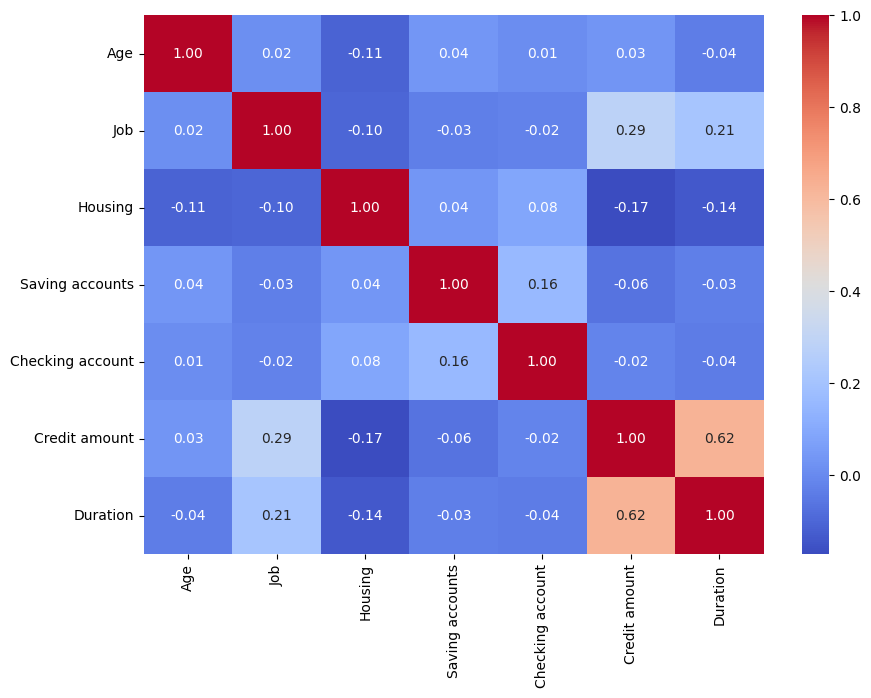

In [23]:
import matplotlib.pyplot as plt

df_corr = df.copy()

df_corr['Housing'] = df_corr['Housing'].map({
    'free': 0,
    'rent': 1,
    'own': 2
})

df_corr['Saving accounts'] = df_corr['Saving accounts'].map({
    'little': 0,
    'moderate': 1,
    'quite rich': 2,
    'rich': 3
})

df_corr['Checking account'] = df_corr['Checking account'].map({
    'little': 0,
    'moderate': 1,
    'rich': 2
})

original_numeric = df_corr[['Age', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration']]

plt.figure(figsize=(10,7))
sns.heatmap(original_numeric.corr(),
            annot=True,
            fmt='.2f',
            cmap='coolwarm')
plt.show()

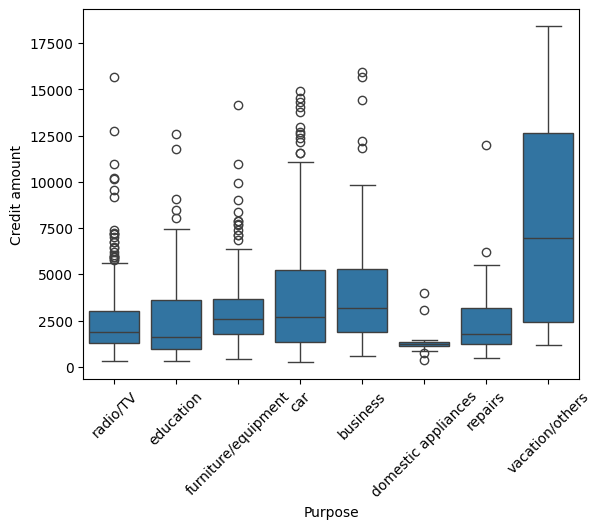

In [24]:
df = pd.read_csv('/credit.csv')

sns.boxplot(data=df, x='Purpose', y='Credit amount')
plt.xticks(rotation=45)
plt.show()

In [25]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_pred))

[[193   4]
 [  1   2]]


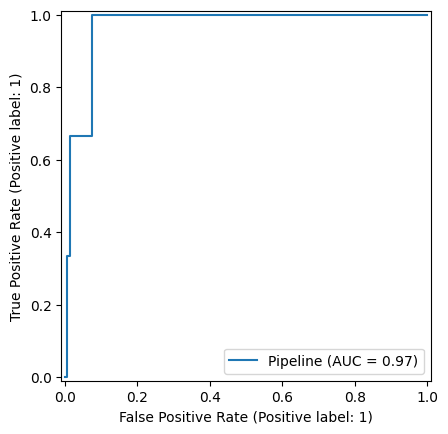

In [26]:
from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_estimator(model, X_test, y_test)
plt.show()

In [27]:
coef = model.named_steps['logreg'].coef_[0]
for feature, weight in zip(X.columns, coef):
  print(feature, round(weight, 3))

Age -1.277
Job -0.22
Credit amount 1.93
Duration 0.644
is_male 0.729
has_own_house -0.239
is_rent -1.177
saving_score -1.132
no_checking_account -4.126
checking_score -2.973
job_risk 0.22
Purpose_car 0.562
Purpose_domestic appliances -0.087
Purpose_education -0.511
Purpose_furniture/equipment -0.964
Purpose_radio/TV -1.271
Purpose_repairs 0.256
Purpose_vacation/others -0.043


In [28]:
# feature_columns = joblib.load('feature_columns.pkl')

def get_user_input():
  age = int(input('Возраст: '))
  #pex = input('Пол (male/female): ')
  job = int(input('Работа (0-3): '))
  housing = input('Жильё (own/rent/free): ')
  saving = input('Накопления (little/moderate/quite rich/rich): ')
  checking = input('Checking account (little/moderate/rich): ')
  credit_amount = float(input('Сумма кредита: '))
  duration = int(input('Срок (мес): '))
  purpose = input(
      'Purpose (car/furniture/equipment/radio/TV/'
      'domestic appliances/repairs/education/business/vacation/others): '
  )

  return age, job, housing, saving, checking, credit_amount, duration, purpose

def preprocess(age, job, housing, saving, checking, credit_amount, duration, purpose):

  #is_male = 1 if sex == 'male' else 0
  has_own_house = 1 if housing == 'own' else 0
  is_rent = 1 if housing == 'rent' else 0

  saving_map = {
      'little': 0,
      'moderate': 1,
      'quite rich': 2,
      'rich': 3
  }
  saving_score = saving_map.get(saving, -1)

  checking_map = {
      'little': 0,
      'moderate': 1,
      'rich': 2
  }
  checking_score = checking_map.get(checking, -1)

  credit_per_month = credit_amount / duration
  credit_to_age = credit_amount / age
  duration_to_age = duration / age
  job_risk = 3 - job

  data = {
      'Age': age,
      'Job': job,
      'Credit amount': credit_amount,
      'Duration': duration,
      #'is_male': is_male,
      'has_own_house': has_own_house,
      'is_rent': is_rent,
      'saving_score': saving_score,
      'checking_score': checking_score,
      'job_risk': job_risk
  }

  df_input = pd.DataFrame([data])

  purpose = purpose.lower().strip()

  for col in feature_columns:
    if col not in df_input.columns:
      df_input[col] = 0

  df_input = df_input.reindex(columns=feature_columns)

  return df_input

def risk_class(p):
  if p < 0.2:
    return 'A'
  elif p < 0.5:
    return 'B'
  else:
    return 'C'

age, job, housing, saving, checking, credit_amount, duration, purpose = get_user_input()

features = preprocess(age, job, housing, saving, checking, credit_amount, duration, purpose)

prob = model.predict_proba(features)[0][1]
risk = risk_class(prob)

print('\nВеротность дефолта:', round(prob, 3))
print('Класс риска:', risk)

if risk == 'C':
  print('Кредит отклонён')
else:
  print('Кредит одобрен')

Возраст: 22
Работа (0-3): 2
Жильё (own/rent/free): own
Накопления (little/moderate/quite rich/rich): little
Checking account (little/moderate/rich): rich
Сумма кредита: 7000
Срок (мес): 15
Purpose (car/furniture/equipment/radio/TV/domestic appliances/repairs/education/business/vacation/others): car

Веротность дефолта: 0.001
Класс риска: A
Кредит одобрен


In [29]:
!pip install streamlit joblib cloudflared --quiet

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 93.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 127.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.0/63.0 kB 4.5 MB/s eta 0:00:00


In [30]:
!pip install shap --quiet

In [31]:
joblib.dump(X.columns.tolist(), "feature_columns.pkl")

['feature_columns.pkl']

In [32]:
%%writefile app.py
import streamlit as st
import shap
import matplotlib.pyplot as plt
import joblib
import pandas as pd
import numpy as np

model = joblib.load("credit_model.pkl")
feature_columns = joblib.load("feature_columns.pkl")

X_dummy = pd.DataFrame(np.zeros((10, len(feature_columns))), columns=feature_columns)
explainer = shap.Explainer(model.named_steps['logreg'], X_dummy)

def preprocess(age, job, housing, saving, checking, credit_amount, duration, purpose):
  has_own_house = 1 if housing == 'own' else 0
  is_rent = 1 if housing == 'rent' else 0

  saving_map = {
      'little': 0,
      'moderate': 1,
      'quite rich': 2,
      'rich': 3
  }

  checking_map = {
      'little': 0,
      'moderate': 1,
      'rich': 2
  }

  data = {
      'Age': age,
      'Job': job,
      'Credit amount': credit_amount,
      'Duration': duration,
      'has_own_house': has_own_house,
      'is_rent': is_rent,
      'saving_score': saving_map.get(saving, -1),
      'checking_score': checking_map.get(checking, -1),
      'job_risk': 3 - job
  }

  df_input = pd.DataFrame([data])

  purpose_col = f'Purpose_{purpose}'
  if purpose_col in feature_columns:
    df_input[purpose_col] = 1

  for col in feature_columns:
    if col not in df_input.columns:
      df_input[col] = 0

  return df_input[feature_columns]

def risk_class(p):
  if p < 0.2:
    return "A"
  elif p < 0.5:
    return "B"
  else:
    return "C"

st.title("Credit risk")

age = st.slider("Возраст", 18, 70, 30)
job = st.slider("Работа (0-3)", 0, 3, 1)
credit_amount = st.number_input("Сумма кредита", min_value=0.0, value=5000.0)
duration = st.slider("Срок (месяцы)", 6, 72, 24)

housing = st.selectbox("Жильё", ["own", "rent", "free"])
saving = st.selectbox("Накопления", ["little", "moderate", "quite rich", "rich"])
checking = st.selectbox("Checking account", ["little", "moderate", "rich"])
purpose = st.selectbox("Категория", ["car", "furniture/equipment", "radio/TV", "education",
     "business", "repairs", "vacation/others", "domestic appliances"])
if st.button("Рассчитать риск"):

  features = preprocess(age, job, housing, saving, checking,
                        credit_amount, duration, purpose)

  prob = model.predict_proba(features)[0][1]
  risk = risk_class(prob)

  st.subheader("Результат")

  st.metric("Вероятность дефолта", f"{prob:.2%}")

  if risk == "A":
    st.success(f"Класс риска: {risk} (Низкий риск)")
  elif risk == "B":
    st.warning(f"Класс риска: {risk} (Средний риск)")
  else:
    st.error(f"Класс риска: {risk} (Высокий риск)")

  shap_values_user = explainer(features)

  st.subheader("Влияние признаков")
  fig, ax = plt.subplots(figsize=(8,5))
  shap.plots.bar(shap_values_user, max_display=10, show=False)
  st.pyplot(fig)


Writing app.py


In [33]:
!streamlit run app.py & npx cloudflared tunnel --url http://localhost:8501



⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋
  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.142.162.47:8501

⠙⠹Need to install the following packages:
cloudflared@0.7.1
Ok to proceed? (y)   Stopping...
^C


In [34]:
!pip install ipython-sql

%load_ext sql
%sql sqlite://

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 67.9 MB/s eta 0:00:00


In [35]:
import sqlite3

conn = sqlite3.connect('credit.db')
df.to_sql('credit_data', conn, if_exists='replace', index=False)
conn.close()

In [36]:
%sql sqlite:///credit.db
%config SqlMagic.style = '_DEPRECATED_DEFAULT'

In [37]:
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,0,67,male,2,own,NaN,little,1169,6,radio/TV
1,1,22,female,2,own,little,moderate,5951,48,radio/TV
2,2,49,male,1,own,little,NaN,2096,12,education
3,3,45,male,2,free,little,little,7882,42,furniture/equipment
4,4,53,male,2,free,little,little,4870,24,car


In [38]:
%%sql
SELECT ROUND(AVG("Credit amount"), 2) AS среднее,
      MIN("Credit amount") AS минимум,
      COUNT(*) AS колво
FROM credit_data
WHERE Purpose = 'car';


   sqlite://
 * sqlite:///credit.db
Done.


среднее,минимум,колво
3768.19,250,337


In [39]:
%%sql
SELECT COUNT(*) AS колво
FROM credit_data
WHERE Purpose = 'car';

   sqlite://
 * sqlite:///credit.db
Done.


колво
337


In [40]:
%%sql
SELECT MIN("Credit amount") AS минимум,
MAX("Credit amount") as максимум
FROM credit_data;

   sqlite://
 * sqlite:///credit.db
Done.


минимум,максимум
250,18424


In [41]:
%%sql
SELECT Purpose,
ROUND(AVG(Duration), 2) AS средний_срок
FROM credit_data
GROUP BY Purpose
ORDER BY средний_срок;

   sqlite://
 * sqlite:///credit.db
Done.


Purpose,средний_срок
domestic appliances,16.83
repairs,19.09
furniture/equipment,19.29
education,19.68
radio/TV,20.05
car,20.81
business,26.94
vacation/others,32.33


In [42]:
%%sql
SELECT Purpose,
COUNT(*) AS название
FROM credit_data
GROUP BY Purpose
ORDER BY название;

   sqlite://
 * sqlite:///credit.db
Done.


Purpose,название
domestic appliances,12
vacation/others,12
repairs,22
education,59
business,97
furniture/equipment,181
radio/TV,280
car,337


In [43]:
%%sql
SELECT Purpose,
      ROUND(AVG("Credit amount"), 2) AS Суммаavg
FROM credit_data
GROUP BY Purpose
ORDER BY Суммаavg DESC
LIMIT 8;

   sqlite://
 * sqlite:///credit.db
Done.


Purpose,Суммаavg
vacation/others,8209.33
business,4158.04
car,3768.19
furniture/equipment,3066.99
education,2879.2
repairs,2728.09
radio/TV,2487.65
domestic appliances,1498.0


In [44]:
%%sql
SELECT CASE
          WHEN Age < 30 THEN '<30'
          WHEN Age BETWEEN 30 AND 50 THEN '30-50'
          ELSE '>50'
        END AS группа,
        ROUND(AVG("Credit amount"), 2) AS среднее
FROM credit_data
GROUP BY
        CASE
          WHEN Age < 30 THEN '<30'
          WHEN Age BETWEEN 30 AND 50 THEN '30-50'
          ELSE '>50'
        END
ORDER BY среднее DESC;

   sqlite://
 * sqlite:///credit.db
Done.


группа,среднее
30-50,3396.76
>50,3296.59
<30,3088.99


In [45]:
%%sql
SELECT *
FROM credit_data
WHERE "Credit amount" > (
  SELECT AVG("Credit amount")
  FROM credit_data
)
LIMIT 10;

   sqlite://
 * sqlite:///credit.db
Done.


Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
1,22,female,2,own,little,moderate,5951,48,radio/TV
3,45,male,2,free,little,little,7882,42,furniture/equipment
4,53,male,2,free,little,little,4870,24,car
5,35,male,1,free,None,None,9055,36,education
7,35,male,3,rent,little,moderate,6948,36,car
9,28,male,3,own,little,moderate,5234,30,car
11,24,female,2,rent,little,little,4308,48,business
17,25,male,2,own,None,little,8072,30,business
18,44,female,3,free,little,moderate,12579,24,car
19,31,male,2,own,quite rich,None,3430,24,radio/TV


In [46]:
%%sql
SELECT
    COUNT(CASE WHEN "Saving accounts" <> 'None' THEN 1 END) AS накопления,
    COUNT(*) AS всего,
    ROUND((CAST(COUNT(CASE WHEN "Saving accounts" <> 'None' THEN 1 END) AS REAL) / CAST(COUNT(*) AS REAL)) * 100, 2) AS процент
FROM credit_data;

   sqlite://
 * sqlite:///credit.db
Done.


накопления,всего,процент
817,1000,81.7


In [47]:
%%sql
SELECT
    ROUND(AVG(CASE WHEN Sex = 'male' THEN "Credit amount" END), 2) AS мужчины,
    ROUND(AVG(CASE WHEN Sex = 'female' THEN "Credit amount" END), 2) AS женщины,
    ROUND(AVG(CASE WHEN Sex = 'male' THEN "Credit amount" END) - AVG(CASE WHEN Sex = 'female' THEN "Credit amount" END), 2) AS разница
FROM credit_data;

   sqlite://
 * sqlite:///credit.db
Done.


мужчины,женщины,разница
3448.04,2877.77,570.27


In [48]:
%%sql
SELECT *
FROM credit_data cd
WHERE "Credit amount" > (
  SELECT AVG("Credit amount")
  FROM credit_data
  WHERE Purpose = cd.Purpose
)
LIMIT 10;

   sqlite://
 * sqlite:///credit.db
Done.


Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
1,22,female,2,own,little,moderate,5951,48,radio/TV
3,45,male,2,free,little,little,7882,42,furniture/equipment
4,53,male,2,free,little,little,4870,24,car
5,35,male,1,free,None,None,9055,36,education
7,35,male,3,rent,little,moderate,6948,36,car
8,61,male,1,own,rich,None,3059,12,radio/TV
9,28,male,3,own,little,moderate,5234,30,car
11,24,female,2,rent,little,little,4308,48,business
17,25,male,2,own,None,little,8072,30,business
18,44,female,3,free,little,moderate,12579,24,car


In [49]:
%%sql
WITH age_groups AS (
    SELECT
      CASE
        WHEN Age < 30 THEN '<30'
        WHEN Age BETWEEN 30 AND 50 THEN '30-50'
        ELSE '>50'
      END AS возрастная_группа,
      Purpose,
      COUNT(*) as количество
    FROM credit_data
    GROUP BY 1, 2
),
ranked_purposes AS(
  SELECT
    возрастная_группа,
    Purpose,
    количество,
    ROW_NUMBER() OVER (PARTITION BY возрастная_группа ORDER BY количество DESC) as rn
  FROM age_groups
)
SELECT
  возрастная_группа,
  Purpose as популярный_purpose,
  количество
FROM ranked_purposes
WHERE rn = 1
ORDER BY возрастная_группа;

   sqlite://
 * sqlite:///credit.db
Done.


возрастная_группа,популярный_purpose,количество
30-50,car,192
<30,radio/TV,117
>50,car,43


In [51]:
%%sql
SELECT *
FROM (
  SELECT *,
    ROW_NUMBER() OVER (PARTITION BY Housing ORDER BY Duration DESC) AS rn
  FROM credit_data
) t
WHERE rn = 1;

   sqlite://
 * sqlite:///credit.db
Done.


Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,rn
373,63,male,3,free,None,None,13756,60,car,1
677,24,male,2,own,moderate,moderate,5595,72,radio/TV,1
973,36,male,2,rent,little,little,7297,60,business,1


In [52]:
%%sql
SELECT Purpose,
  AVG("Credit amount") AS avg_credit
FROM credit_data
GROUP BY Purpose
HAVING AVG("Credit amount") > (
  SELECT AVG("Credit amount") * 1.2
  FROM credit_data
);

   sqlite://
 * sqlite:///credit.db
Done.


Purpose,avg_credit
business,4158.041237113402
vacation/others,8209.333333333334


In [56]:
%%sql
SELECT *
FROM credit_data
WHERE Duration > (
  SELECT AVG(Duration) FROM credit_data
)
AND "Credit amount" < (
  SELECT AVG("Credit amount") FROM credit_data
)
LIMIT 10;

   sqlite://
 * sqlite:///credit.db
Done.


Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
6,53,male,2,own,quite rich,None,2835,24,furniture/equipment
13,60,male,1,own,little,little,1199,24,car
15,32,female,1,own,moderate,little,1282,24,radio/TV
16,53,male,2,own,None,None,2424,24,radio/TV
40,30,male,3,own,quite rich,None,2333,30,radio/TV
46,39,male,2,own,quite rich,None,2299,36,radio/TV
50,29,male,1,own,None,moderate,2333,24,furniture/equipment
54,57,male,2,free,little,moderate,2225,36,car
62,61,male,3,free,little,moderate,1953,36,business
64,26,female,2,own,little,None,3181,24,radio/TV


In [60]:
%%sql
SELECT *
FROM (
  SELECT *,
    PERCENT_RANK() OVER (ORDER BY "Credit amount") AS pr
  FROM credit_data
) t
WHERE pr >= 0.95
LIMIT 10;

   sqlite://
 * sqlite:///credit.db
Done.


Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,pr
805,24,male,2,own,little,little,9271,36,car,0.950950950950951
881,48,male,2,free,None,None,9277,24,car,0.9519519519519519
808,55,male,3,free,little,moderate,9283,42,car,0.9529529529529529
291,28,male,3,rent,little,moderate,9398,36,car,0.953953953953954
78,39,male,1,own,None,None,9436,54,car,0.954954954954955
57,31,female,2,own,little,None,9566,36,radio/TV,0.955955955955956
180,28,male,2,own,little,None,9572,36,business,0.9569569569569569
812,24,male,2,own,little,little,9629,36,car,0.9579579579579579
684,31,male,1,own,moderate,moderate,9857,36,business,0.958958958958959
295,26,female,2,own,little,moderate,9960,48,furniture/equipment,0.95995995995996


In [64]:
%%sql
SELECT Purpose,
  "Credit amount",
  RANK() OVER (PARTITION BY Purpose ORDER BY "Credit amount" DESC) AS rank_in_purpose
FROM credit_data
LIMIT 10;

   sqlite://
 * sqlite:///credit.db
Done.


Purpose,Credit amount,rank_in_purpose
business,15945,1
business,15672,2
business,14421,3
business,12204,4
business,11816,5
business,9857,6
business,9572,7
business,8648,8
business,8318,9
business,8072,10
